Identify outliers using IQR and Z-score methods by manually computing quartiles, standard deviations, and thresholds without using built-in statistical functions, and visualize them using a custom plotting approach.


Feature: age
Mean: 52.91
Standard Deviation: 14.034
Q1: 41.75
Median: 55.5
Q3: 65.25
IQR: 23.5
IQR Lower Threshold: 6.5
IQR Upper Threshold: 100.5
Z-score Lower Threshold: 10.807
Z-score Upper Threshold: 95.013
IQR Outliers: 0
Z-score Outliers: 0
IQR Outlier Values: []
Z-score Outlier Values: []


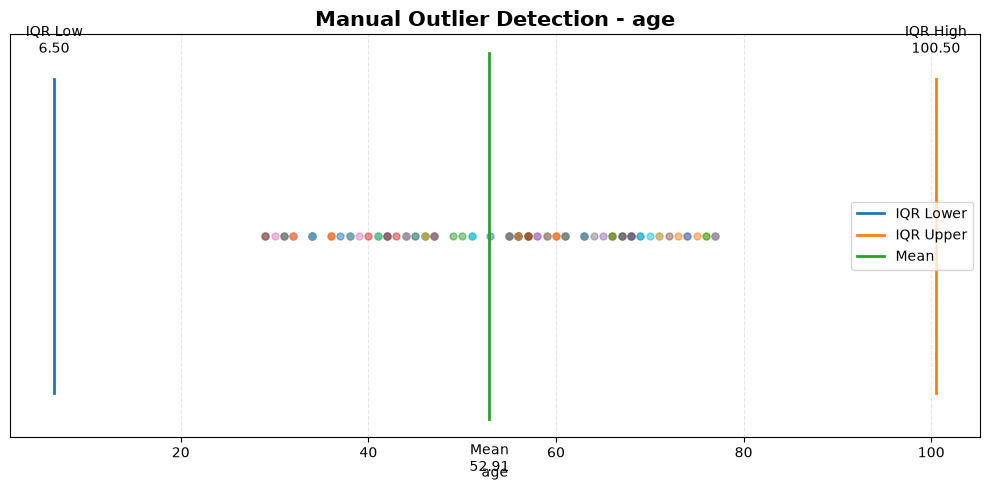


Feature: trestbps
Mean: 150.21
Standard Deviation: 31.728
Q1: 119.75
Median: 153.0
Q3: 177.5
IQR: 57.75
IQR Lower Threshold: 33.125
IQR Upper Threshold: 264.125
Z-score Lower Threshold: 55.027
Z-score Upper Threshold: 245.393
IQR Outliers: 0
Z-score Outliers: 0
IQR Outlier Values: []
Z-score Outlier Values: []


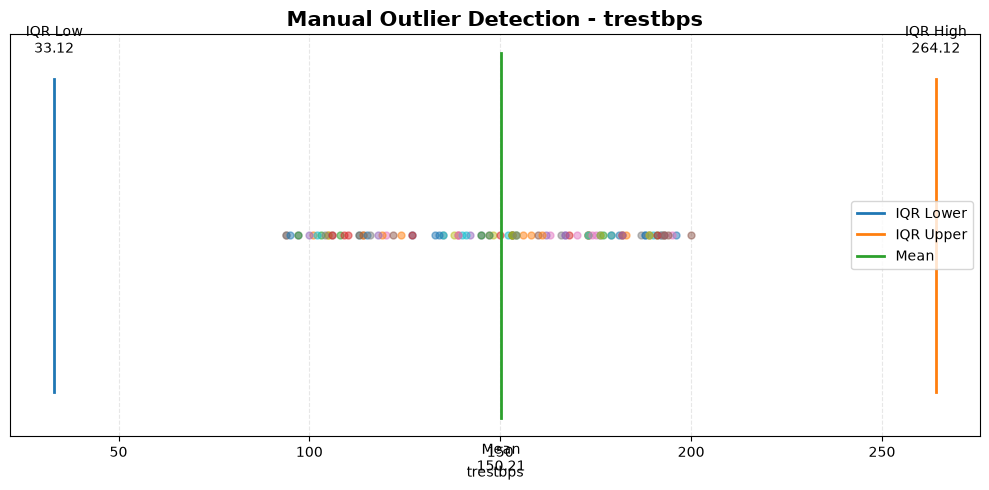


Feature: chol
Mean: 355.55
Standard Deviation: 130.771
Q1: 231.0
Median: 367.0
Q3: 469.25
IQR: 238.25
IQR Lower Threshold: -126.375
IQR Upper Threshold: 826.625
Z-score Lower Threshold: -36.764
Z-score Upper Threshold: 747.864
IQR Outliers: 0
Z-score Outliers: 0
IQR Outlier Values: []
Z-score Outlier Values: []


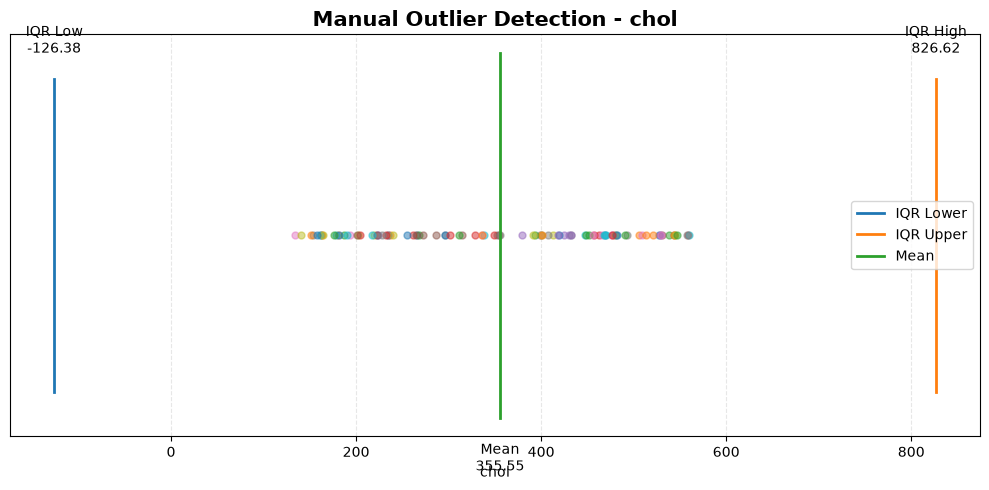


Feature: thalach
Mean: 144.75
Standard Deviation: 35.337
Q1: 114.5
Median: 148.5
Q3: 175.0
IQR: 60.5
IQR Lower Threshold: 23.75
IQR Upper Threshold: 265.75
Z-score Lower Threshold: 38.739
Z-score Upper Threshold: 250.761
IQR Outliers: 0
Z-score Outliers: 0
IQR Outlier Values: []
Z-score Outlier Values: []


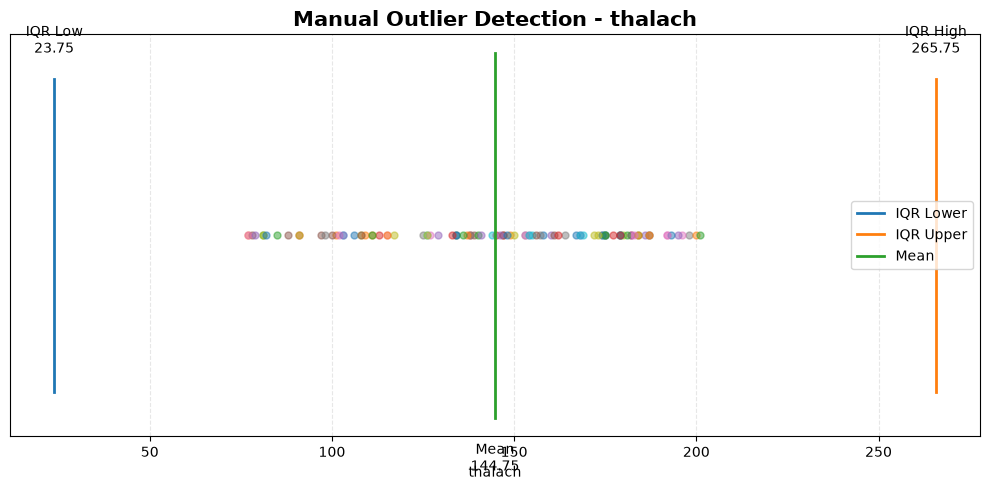


Feature: oldpeak
Mean: 3.106
Standard Deviation: 1.695
Q1: 1.7
Median: 3.05
Q3: 4.425
IQR: 2.725
IQR Lower Threshold: -2.388
IQR Upper Threshold: 8.513
Z-score Lower Threshold: -1.979
Z-score Upper Threshold: 8.191
IQR Outliers: 0
Z-score Outliers: 0
IQR Outlier Values: []
Z-score Outlier Values: []


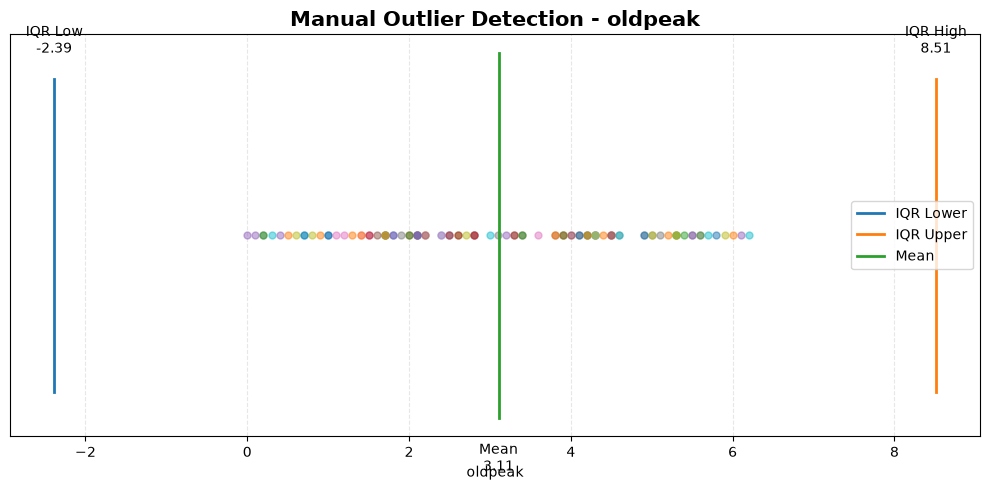

In [1]:
import pandas as pd
import math
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Load dataset
df = pd.read_csv("heart_disease_with_risk_factor.csv")

# Numerical columns
numerical_columns = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

# Manual mean
def manual_mean(values):

    total = 0

    for value in values:
        total += value

    return total / len(values)


# Manual standard deviation
def manual_std(values):

    mean = manual_mean(values)

    squared_difference = 0

    for value in values:

        squared_difference += (
            (value - mean) ** 2
        )

    variance = (
        squared_difference / len(values)
    )

    return math.sqrt(variance)


# Manual median
def manual_median(values):

    sorted_values = values.copy()

    for i in range(len(sorted_values)):

        for j in range(i + 1, len(sorted_values)):

            if sorted_values[i] > sorted_values[j]:

                sorted_values[i], sorted_values[j] = (
                    sorted_values[j],
                    sorted_values[i]
                )

    n = len(sorted_values)

    if n % 2 == 1:

        return sorted_values[n // 2]

    else:

        return (
            sorted_values[n // 2 - 1]
            + sorted_values[n // 2]
        ) / 2


# Manual percentile
def manual_percentile(values, percentage):

    sorted_values = values.copy()

    for i in range(len(sorted_values)):

        for j in range(i + 1, len(sorted_values)):

            if sorted_values[i] > sorted_values[j]:

                sorted_values[i], sorted_values[j] = (
                    sorted_values[j],
                    sorted_values[i]
                )

    position = (
        (len(sorted_values) - 1)
        * percentage
    )

    lower = int(position)
    upper = lower + 1

    if upper >= len(sorted_values):

        return sorted_values[lower]

    fraction = position - lower

    return (
        sorted_values[lower]
        +
        fraction
        * (
            sorted_values[upper]
            - sorted_values[lower]
        )
    )


# Detect outliers
for column in numerical_columns:

    values = []

    for value in df[column]:

        if pd.notna(value):

            values.append(float(value))

    if len(values) == 0:
        continue

    # Calculate statistics
    mean = manual_mean(values)

    std = manual_std(values)

    q1 = manual_percentile(
        values,
        0.25
    )

    q3 = manual_percentile(
        values,
        0.75
    )

    median = manual_median(values)

    # Calculate IQR
    iqr = q3 - q1

    # IQR thresholds
    lower_iqr = q1 - (
        1.5 * iqr
    )

    upper_iqr = q3 + (
        1.5 * iqr
    )

    # Z-score thresholds
    lower_z = mean - (
        3 * std
    )

    upper_z = mean + (
        3 * std
    )

    # Find IQR outliers
    iqr_outliers = []

    for value in values:

        if (
            value < lower_iqr
            or value > upper_iqr
        ):

            iqr_outliers.append(value)

    # Find Z-score outliers
    z_outliers = []

    for value in values:

        if std != 0:

            z_score = (
                value - mean
            ) / std

            if abs(z_score) > 3:

                z_outliers.append(value)

    # Print results
    print("\n" + "=" * 60)
    print("Feature:", column)
    print("=" * 60)

    print("Mean:", round(mean, 3))
    print("Standard Deviation:", round(std, 3))
    print("Q1:", round(q1, 3))
    print("Median:", round(median, 3))
    print("Q3:", round(q3, 3))
    print("IQR:", round(iqr, 3))

    print(
        "IQR Lower Threshold:",
        round(lower_iqr, 3)
    )

    print(
        "IQR Upper Threshold:",
        round(upper_iqr, 3)
    )

    print(
        "Z-score Lower Threshold:",
        round(lower_z, 3)
    )

    print(
        "Z-score Upper Threshold:",
        round(upper_z, 3)
    )

    print(
        "IQR Outliers:",
        len(iqr_outliers)
    )

    print(
        "Z-score Outliers:",
        len(z_outliers)
    )

    print(
        "IQR Outlier Values:",
        iqr_outliers
    )

    print(
        "Z-score Outlier Values:",
        z_outliers
    )

    # Create custom plot
    fig, ax = plt.subplots(
        figsize=(10, 5)
    )

    # Draw all data points
    for i in range(len(values)):

        value = values[i]

        ax.plot(
            value,
            1,
            marker="o",
            markersize=5,
            alpha=0.5
        )

    # Draw IQR limits
    ax.plot(
        [lower_iqr, lower_iqr],
        [0.7, 1.3],
        linewidth=2,
        label="IQR Lower"
    )

    ax.plot(
        [upper_iqr, upper_iqr],
        [0.7, 1.3],
        linewidth=2,
        label="IQR Upper"
    )

    # Draw mean
    ax.plot(
        [mean, mean],
        [0.65, 1.35],
        linewidth=2,
        label="Mean"
    )

    # Highlight IQR outliers
    for value in iqr_outliers:

        ax.plot(
            value,
            1,
            marker="o",
            markersize=9,
            markerfacecolor="red",
            markeredgecolor="black"
        )

    # Highlight Z-score outliers
    for value in z_outliers:

        ax.plot(
            value,
            1.05,
            marker="x",
            markersize=10,
            markeredgewidth=2
        )

    # Add labels
    ax.text(
        lower_iqr,
        1.35,
        f"IQR Low\n{lower_iqr:.2f}",
        ha="center"
    )

    ax.text(
        upper_iqr,
        1.35,
        f"IQR High\n{upper_iqr:.2f}",
        ha="center"
    )

    ax.text(
        mean,
        0.55,
        f"Mean\n{mean:.2f}",
        ha="center"
    )

    ax.set_title(
        f"Manual Outlier Detection - {column}",
        fontsize=15,
        fontweight="bold"
    )

    ax.set_xlabel(column)

    ax.set_yticks([])

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.3
    )

    ax.legend()

    plt.tight_layout()
    plt.show()